# Project 5 · A live training dashboard (City Hospital)

> *"Our trial screening model reaches a training loss of 0.000, and the doctors do not trust it. Build a page where our data team can watch training and validation loss live, fix the curves, and see how many cancers the model finds."*

**How this notebook is organised**

| Part | What happens |
|---|---|
| **A** | Write `trainer.py`, the training engine. It knows nothing about Streamlit. |
| **B** | Run the 5 experiments right here in Colab, with all the graphs. This works even if the dashboard link gives trouble. |
| **C** | Write `app.py` (the Streamlit dashboard) and open it in your browser through a tunnel. |
| **D** | The one-time final test, plus a `REPORT.md` template. |

Run the cells top to bottom. No GPU is needed; every run takes a few seconds on a CPU.

In [1]:
# Colab already has torch, sklearn, pandas and matplotlib. Streamlit is the only thing missing.
!pip -q install streamlit

---
# Part A · `trainer.py`, the engine

`%%writefile` saves the cell as a real file, so both this notebook **and** the Streamlit page can `import trainer`.

The 4 things to understand in this file:
1. **Label flip:** sklearn says `0 = malignant`. We flip it so `1 = malignant`, as the project asks. Without this, "cancers found" would actually count healthy patients.
2. **Scaler fitted on training rows only.** Then the same numbers are applied to val/test. Fitting on all rows would leak information from val/test into training.
3. **`on_epoch` callback:** after each epoch, `train()` calls whatever function you pass in. The page passes a "redraw the chart" function; this notebook passes nothing. That's why the same engine works in both places.
4. **Full batch** (`batch_size=341` = every training row): one weight update per epoch, the same setup the slides used. Because of this, your curves should look like the ones on the slides.

In [2]:
%%writefile trainer.py
"""
trainer.py - the training engine for Project 5 (City Hospital).

This file knows NOTHING about Streamlit. It trains a model and, after every
epoch, calls back whatever function you give it (on_epoch). The Streamlit page
passes a function that redraws the chart; a notebook can pass nothing at all.
"""
import copy
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix

# Default settings = the "256 neurons, no fixes" run from the slides
DEFAULTS = dict(
    hidden=256,        # neurons in each of the 2 hidden layers
    dropout=0.0,       # 0.0 = dropout off
    weight_decay=0.0,  # 0.0 = weight decay off
    lr=0.001,          # learning rate for AdamW
    epochs=300,        # maximum number of epochs
    batch_size=341,   # 341 = all training rows = one update per epoch (full batch)
    patience=0,        # 0 = early stopping off
    scale=True,        # StandardScaler on/off
    seed=0,
)


# ---------------------------------------------------------------- data
def load_data(scale=True, seed=0):
    """569 patients, 30 measurements. Split 60/20/20 -> 341/114/114, stratified."""
    ds = load_breast_cancer()
    X = ds.data.astype(np.float32)
    # sklearn uses 0 = malignant, 1 = benign. The project wants malignant = 1,
    # so we flip the labels. Forgetting this makes "cancers found" mean "healthy found".
    y = (1 - ds.target).astype(np.int64)

    X_tr, X_tmp, y_tr, y_tmp = train_test_split(
        X, y, test_size=0.4, stratify=y, random_state=seed)
    X_va, X_te, y_va, y_te = train_test_split(
        X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=seed)

    raw_va = X_va.copy()  # unscaled copy, so the page can show real measurements
    if scale:
        # fit on TRAINING rows only, then apply the same numbers everywhere
        scaler = StandardScaler().fit(X_tr)
        X_tr, X_va, X_te = (scaler.transform(a).astype(np.float32) for a in (X_tr, X_va, X_te))

    t = torch.tensor
    return dict(X_tr=t(X_tr), y_tr=t(y_tr), X_va=t(X_va), y_va=t(y_va),
                X_te=t(X_te), y_te=t(y_te), raw_va=raw_va,
                feature_names=list(ds.feature_names))


# ---------------------------------------------------------------- model
def build_model(hidden, dropout, n_in=30):
    return nn.Sequential(
        nn.Linear(n_in, hidden), nn.ReLU(), nn.Dropout(dropout),
        nn.Linear(hidden, hidden), nn.ReLU(), nn.Dropout(dropout),
        nn.Linear(hidden, 2),          # 2 outputs: benign (0), malignant (1)
    )


# ---------------------------------------------------------------- training
def train(cfg, data, on_epoch=None):
    """Train with the settings in cfg. Returns (model, hist, info)."""
    cfg = {**DEFAULTS, **cfg}
    torch.manual_seed(cfg["seed"])

    model = build_model(cfg["hidden"], cfg["dropout"])
    opt = torch.optim.AdamW(model.parameters(), lr=cfg["lr"],
                            weight_decay=cfg["weight_decay"])
    loss_fn = nn.CrossEntropyLoss()
    loader = DataLoader(TensorDataset(data["X_tr"], data["y_tr"]),
                        batch_size=cfg["batch_size"], shuffle=True,
                        generator=torch.Generator().manual_seed(cfg["seed"]))

    hist = {"train": [], "val": [], "train_acc": [], "val_acc": []}
    best_val, best_state, best_epoch, wait = float("inf"), None, 0, 0

    for epoch in range(1, cfg["epochs"] + 1):
        model.train()                                   # dropout ON
        for xb, yb in loader:
            loss = loss_fn(model(xb), yb)
            opt.zero_grad(); loss.backward(); opt.step()

        model.eval()                                    # dropout OFF for measuring
        with torch.no_grad():
            out_tr, out_va = model(data["X_tr"]), model(data["X_va"])
            hist["train"].append(loss_fn(out_tr, data["y_tr"]).item())
            hist["val"].append(loss_fn(out_va, data["y_va"]).item())
            hist["train_acc"].append((out_tr.argmax(1) == data["y_tr"]).float().mean().item())
            hist["val_acc"].append((out_va.argmax(1) == data["y_va"]).float().mean().item())

        if hist["val"][-1] < best_val:                  # remember the best weights
            best_val, best_epoch, wait = hist["val"][-1], epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1

        if on_epoch:                                    # tell the page (or anyone) about it
            on_epoch(epoch, hist)

        if cfg["patience"] and wait >= cfg["patience"]:  # early stopping
            break

    # With early stopping we ship the best checkpoint, not the last epoch.
    # (best_state stays None only if validation loss was never a real number.)
    if cfg["patience"] and best_state is not None:
        model.load_state_dict(best_state)

    info = dict(epochs_run=epoch, best_val=best_val, best_epoch=best_epoch)
    return model, hist, info


# ---------------------------------------------------------------- diagnosis
def diagnose(hist):
    """Rule from Part 2, plus one extra check for jumpy curves."""
    tr, va = hist["train"], hist["val"]
    # A loss of NaN/inf means training blew up. Every comparison below is False for
    # NaN, so without this line a blown-up run would be called "healthy".
    if not np.all(np.isfinite(tr + va)):
        return "unstable"
    # Extra check: with one update per epoch, a healthy TRAINING loss only goes down.
    # If it climbs back more than 0.5 above the lowest value it already reached,
    # the steps are too big: learning rate too high, or features not scaled.
    lowest_so_far = np.minimum.accumulate(tr)
    if max(np.array(tr) - lowest_so_far) > 0.5:
        return "unstable"
    if tr[-1] > 0.3:
        return "underfitting"
    if va[-1] > 1.3 * min(va):
        return "overfitting"
    return "healthy"


# ---------------------------------------------------------------- evaluation
def predict_proba(model, X):
    """Probability of malignant (class 1) for each row."""
    model.eval()
    with torch.no_grad():
        return torch.softmax(model(X), dim=1)[:, 1].numpy()


def evaluate(model, X, y, threshold=0.5):
    """Counts the doctors care about. A patient is flagged malignant if prob >= threshold."""
    probs = predict_proba(model, X)
    y = y.numpy()
    pred = (probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return dict(accuracy=float((pred == y).mean()),
                cancers_found=int(tp), cancers_total=int(tp + fn), missed=int(fn),
                false_alarms=int(fp), probs=probs, pred=pred, y=y,
                cm=np.array([[tn, fp], [fn, tp]]))

Overwriting trainer.py


---
# Part B · The experiments, in the notebook

First we look at the data, then we run the 5 experiments from the slides, **one change at a time**.

In [3]:
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import roc_curve, roc_auc_score
import trainer
importlib.reload(trainer)      # picks up changes if you edit trainer.py and re-run

TRAIN_C, VAL_C = "#E8833A", "#3A7DE8"
data = trainer.load_data(scale=True)
print("train", tuple(data["X_tr"].shape), "| val", tuple(data["X_va"].shape), "| test", tuple(data["X_te"].shape))
for part in ["tr", "va", "te"]:
    y = data[f"y_{part}"].numpy()
    print(f"  {part}: {y.sum():3d} malignant, {(y == 0).sum():3d} benign")

train (341, 30) | val (114, 30) | test (114, 30)
  tr: 127 malignant, 214 benign
  va:  43 malignant,  71 benign
  te:  42 malignant,  72 benign


### 📊 Extra graph 1: why scaling matters
The 30 measurements live on very different scales: some are around 0.001, others around 2,500. The left plot uses a **log scale**, so each step on the y-axis is ×10.

With unscaled inputs, one optimiser step is huge for the big features and tiny for the small ones. That's exactly the "jumps around" trap in experiment 5. The right plot shows the same features after `StandardScaler`: all centred on 0 with a similar spread.

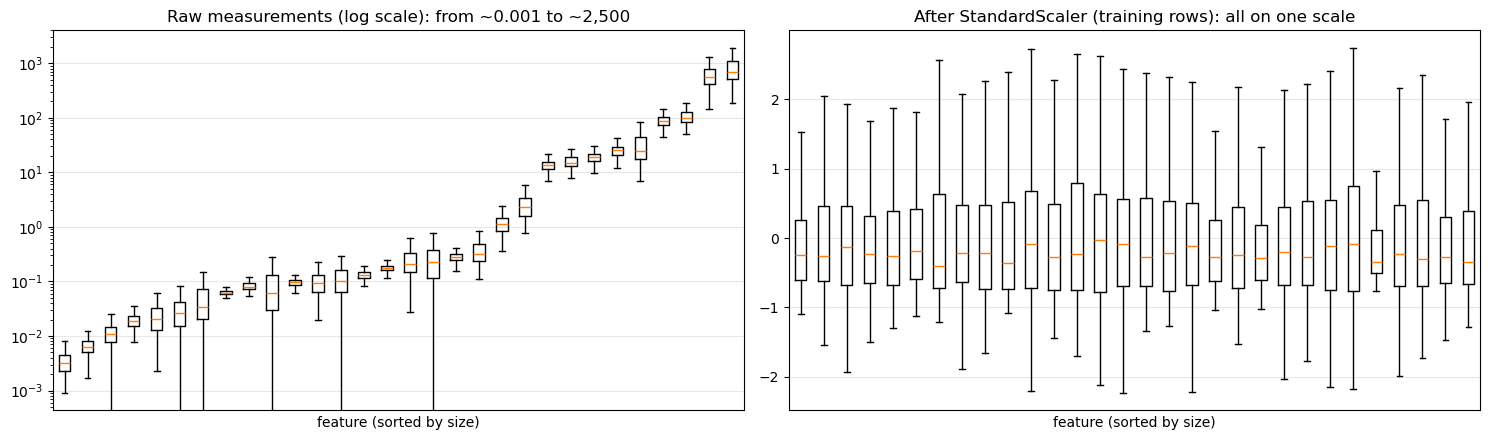

In [4]:
raw = load_breast_cancer().data
scaled = data["X_tr"].numpy()
order = np.argsort(raw.mean(0))       # sort features from smallest to largest

fig, (a1, a2) = plt.subplots(1, 2, figsize=(15, 4.5))
a1.boxplot(raw[:, order], showfliers=False)
a1.set_yscale("log"); a1.set_title("Raw measurements (log scale): from ~0.001 to ~2,500")
a2.boxplot(scaled[:, order], showfliers=False)
a2.set_title("After StandardScaler (training rows): all on one scale")
for a in (a1, a2):
    a.set_xlabel("feature (sorted by size)"); a.set_xticks([]); a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("p5_scaling.png", dpi=120); plt.show()

### The 5 experiments (one change at a time)
| # | Change | Why |
|---|---|---|
| 1 | 256 neurons, no fixes | the baseline the doctors don't trust |
| 2 | + dropout 0.3, weight decay 0.05 | the "usual" fixes for overfitting |
| 3 | + early stopping (patience 20) | stop when validation stops improving |
| 4 | 16 neurons + all fixes | a smaller model, so less room to memorise |
| 5 | same as 4, **not scaled** | the trap |

In [5]:
experiments = {
    "1 · 256, no fixes":        dict(),
    "2 · + dropout & decay":    dict(dropout=0.3, weight_decay=0.05),
    "3 · + early stopping":     dict(dropout=0.3, weight_decay=0.05, patience=20),
    "4 · 16 neurons, all fixes": dict(hidden=16, dropout=0.3, weight_decay=0.05, patience=20),
    "5 · same, NOT scaled":     dict(hidden=16, dropout=0.3, weight_decay=0.05, patience=20, scale=False),
}

runs, rows = {}, []
for name, cfg in experiments.items():
    d = trainer.load_data(scale=cfg.get("scale", True))
    model, hist, info = trainer.train(cfg, d)
    ev = trainer.evaluate(model, d["X_va"], d["y_va"])        # validation only!
    verdict = trainer.diagnose(hist)
    runs[name] = dict(model=model, hist=hist, info=info, data=d, cfg=cfg, verdict=verdict)
    rows.append({"run": name, "diagnosis": verdict, "epochs run": info["epochs_run"],
                 "best val loss": f"{info['best_val']:.3f} @ {info['best_epoch']}",
                 "cancers found": f"{ev['cancers_found']} of {ev['cancers_total']}",
                 "false alarms": ev["false_alarms"]})

results = pd.DataFrame(rows)
results.to_csv("experiments_notebook.csv", index=False)
results

,run,diagnosis,epochs run,best val loss,cancers found,false alarms
0,"1 · 256, no fixes",overfitting,300,0.125 @ 23,41 of 43,3
1,2 · + dropout & decay,overfitting,300,0.131 @ 24,40 of 43,2
2,3 · + early stopping,healthy,44,0.131 @ 24,40 of 43,3
3,"4 · 16 neurons, all fixes",healthy,177,0.129 @ 157,40 of 43,1
4,"5 · same, NOT scaled",unstable,27,0.430 @ 7,33 of 43,2


### 📊 Graph 2: the learning curves of all 5 runs
Read each one with the Part 2 rules. The grey dotted line marks the best validation epoch. Note how **dropout + decay alone (run 2) still overfits**: early stopping and a smaller model do the real work here. That's the honest lesson from the slides.

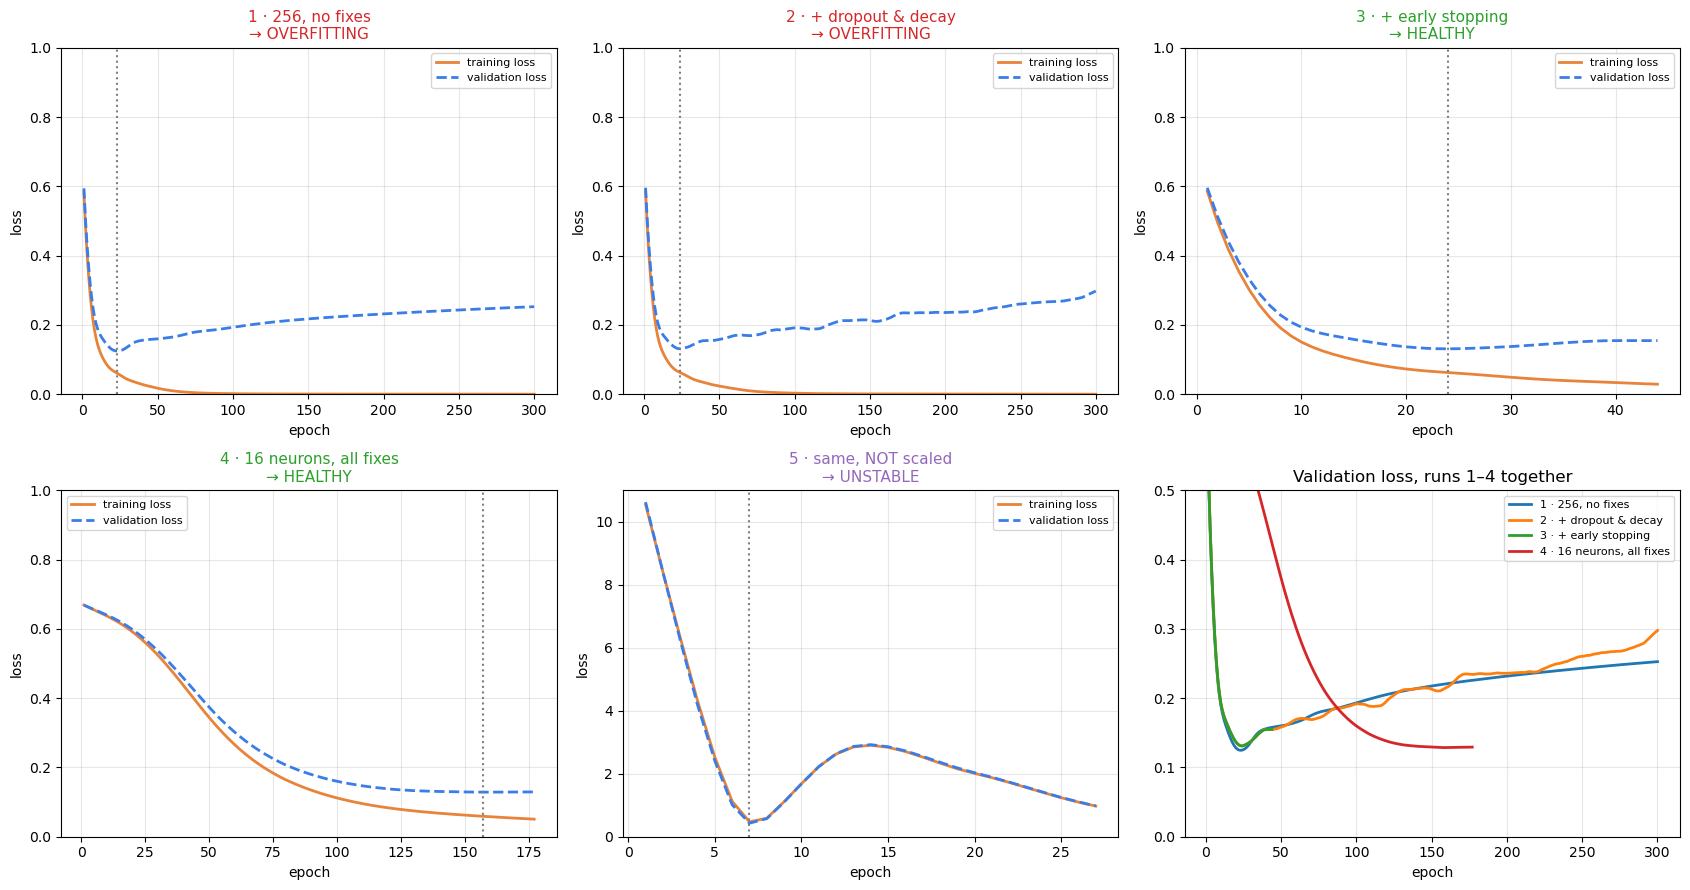

In [6]:
colors_v = {"overfitting": "#D62728", "healthy": "#2CA02C", "underfitting": "#FF7F0E", "unstable": "#9467BD"}
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, (name, r) in zip(axes.ravel(), runs.items()):
    h, info = r["hist"], r["info"]
    ep = range(1, len(h["train"]) + 1)
    ax.plot(ep, h["train"], color=TRAIN_C, lw=2, label="training loss")
    ax.plot(ep, h["val"], color=VAL_C, lw=2, ls="--", label="validation loss")
    ax.axvline(info["best_epoch"], color="grey", ls=":")
    ax.set_title(f"{name}\n→ {r['verdict'].upper()}", color=colors_v[r["verdict"]], fontsize=11)
    ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    ax.set_ylim(0, 1.0 if "NOT" not in name else 11)

# 6th panel: all validation curves together
ax = axes.ravel()[5]
for name, r in runs.items():
    if "NOT" in name:
        continue      # leave out the unscaled run, it would squash the y-axis
    ax.plot(range(1, len(r["hist"]["val"]) + 1), r["hist"]["val"], lw=2, label=name)
ax.set_ylim(0, 0.5); ax.set_title("Validation loss, runs 1–4 together")
ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("p5_experiments.png", dpi=120); plt.show()

### 📊 Graph 3: cancers missed and false alarms per run
For the hospital, these two numbers matter more than the loss. **A missed cancer is far worse than a false alarm.** A false alarm means one extra check; a miss means a sick patient is sent home.

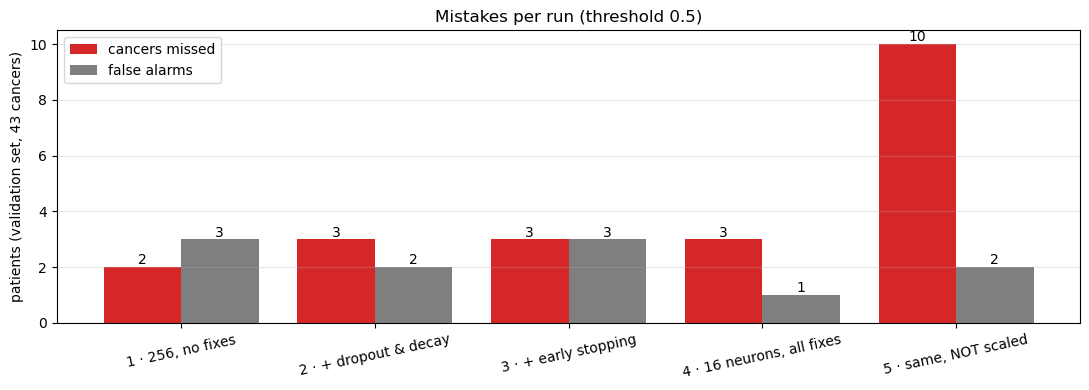

In [7]:
miss, fa = [], []
for r in runs.values():
    e = trainer.evaluate(r["model"], r["data"]["X_va"], r["data"]["y_va"])
    miss.append(e["missed"]); fa.append(e["false_alarms"])

x = np.arange(len(runs))
plt.figure(figsize=(11, 4))
plt.bar(x - 0.2, miss, 0.4, label="cancers missed", color="#D62728")
plt.bar(x + 0.2, fa, 0.4, label="false alarms", color="#7F7F7F")
for i in range(len(x)):
    plt.text(x[i] - 0.2, miss[i] + 0.1, miss[i], ha="center"); plt.text(x[i] + 0.2, fa[i] + 0.1, fa[i], ha="center")
plt.xticks(x, list(runs), rotation=12); plt.ylabel("patients (validation set, 43 cancers)")
plt.title("Mistakes per run (threshold 0.5)"); plt.legend(); plt.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.savefig("p5_mistakes.png", dpi=120); plt.show()

### 📊 Graph 4: a closer look at the chosen model (run 4), on the validation set
- **Probability spread:** benign patients should pile up near 0, malignant ones near 1. Patients in the middle are the uncertain ones.
- **ROC curve:** every possible threshold at once. AUC 1.0 = perfect, 0.5 = coin flip.
- **Threshold trade-off:** lowering the threshold below 0.5 catches more cancers at the cost of more false alarms. This is the first thing the doctors would change.

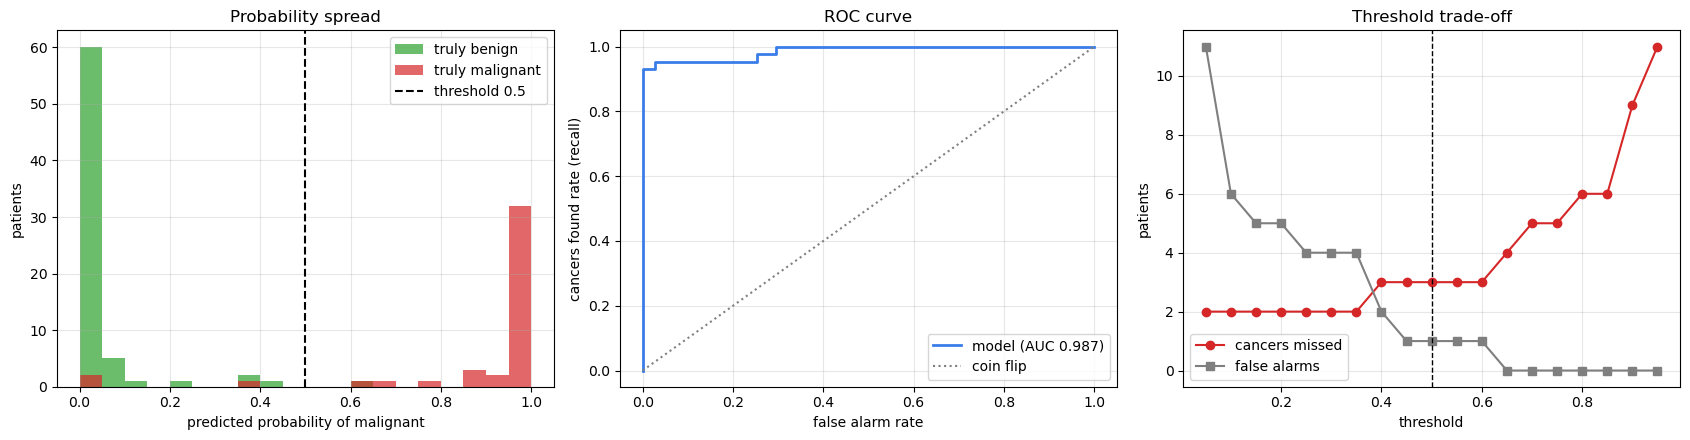

In [8]:
best = runs["4 · 16 neurons, all fixes"]
ev = trainer.evaluate(best["model"], best["data"]["X_va"], best["data"]["y_va"])

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
bins = np.linspace(0, 1, 21)
axes[0].hist(ev["probs"][ev["y"] == 0], bins=bins, alpha=0.7, color="#2CA02C", label="truly benign")
axes[0].hist(ev["probs"][ev["y"] == 1], bins=bins, alpha=0.7, color="#D62728", label="truly malignant")
axes[0].axvline(0.5, color="black", ls="--", label="threshold 0.5")
axes[0].set_xlabel("predicted probability of malignant"); axes[0].set_ylabel("patients")
axes[0].set_title("Probability spread"); axes[0].legend()

fpr, tpr, _ = roc_curve(ev["y"], ev["probs"]); auc = roc_auc_score(ev["y"], ev["probs"])
axes[1].plot(fpr, tpr, color=VAL_C, lw=2, label=f"model (AUC {auc:.3f})")
axes[1].plot([0, 1], [0, 1], color="grey", ls=":", label="coin flip")
axes[1].set_xlabel("false alarm rate"); axes[1].set_ylabel("cancers found rate (recall)")
axes[1].set_title("ROC curve"); axes[1].legend()

ts = np.round(np.arange(0.05, 0.96, 0.05), 2)
tr_rows = [trainer.evaluate(best["model"], best["data"]["X_va"], best["data"]["y_va"], t) for t in ts]
axes[2].plot(ts, [e["missed"] for e in tr_rows], "o-", color="#D62728", label="cancers missed")
axes[2].plot(ts, [e["false_alarms"] for e in tr_rows], "s-", color="#7F7F7F", label="false alarms")
axes[2].axvline(0.5, color="black", ls="--", lw=1)
axes[2].set_xlabel("threshold"); axes[2].set_ylabel("patients"); axes[2].set_title("Threshold trade-off")
axes[2].legend()
for a in axes: a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("p5_chosen_model.png", dpi=120); plt.show()

---
# Part C · The live dashboard (`app.py`)

How the page works:
- **Sidebar:** all the settings, plus a **Train** button.
- **`st.empty()`** is a placeholder. The `redraw()` callback replaces the chart inside it every 5 epochs, which is what makes it look live.
- **`st.session_state`** keeps the experiments table, the last model and the final-test result between clicks. Streamlit re-runs the whole script on every click, so without it everything would reset.
- **Extra graph tabs:** accuracy curves, generalisation gap, confusion matrix, probability spread, ROC curve, threshold trade-off.
- The **threshold slider** works without retraining. Move it and watch "cancers found" and "false alarms" change.

In [9]:
%%writefile app.py
"""
app.py - City Hospital live training dashboard (Project 5).
Run with:  streamlit run app.py
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import streamlit as st
from sklearn.metrics import roc_curve, roc_auc_score

import trainer

st.set_page_config(page_title="City Hospital · training dashboard", layout="wide")
COLORS = ["#E8833A", "#3A7DE8"]          # orange = training, blue = validation
VERDICT = {
    "overfitting":  ("error",   "Overfitting: training loss keeps falling while validation loss climbs back up. Try early stopping, a smaller model, or more regularisation."),
    "underfitting": ("warning", "Underfitting: training loss is still above 0.3. The model is too weak or trained too little."),
    "unstable":     ("warning", "Unstable: the loss jumps back up. The steps are too big. Lower the learning rate or switch scaling on."),
    "healthy":      ("success", "Healthy: both losses fell together and validation stayed close to its best."),
}

# session_state survives between button clicks (Streamlit re-runs the whole script on every click)
if "runs" not in st.session_state:
    st.session_state.runs = []       # the experiments table
if "final" not in st.session_state:
    st.session_state.final = None    # the one-time final test result


@st.cache_resource
def get_data(scale):
    # cached: the data is loaded once per scaling choice, not on every click
    return trainer.load_data(scale=scale)


# ---------------------------------------------------------------- sidebar
with st.sidebar:
    st.header("Settings")
    hidden = st.select_slider("Neurons per hidden layer", [4, 8, 16, 32, 64, 128, 256], value=256)
    dropout = st.slider("Dropout", 0.0, 0.6, 0.0, 0.05)
    weight_decay = st.select_slider("Weight decay", [0.0, 0.001, 0.01, 0.05, 0.1, 0.5], value=0.0)
    lr = st.select_slider("Learning rate", [0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03, 0.1], value=0.001)
    epochs = st.slider("Max epochs", 50, 500, 300, 50)
    use_es = st.checkbox("Early stopping", value=False)
    patience = st.slider("Patience (epochs)", 5, 50, 20, disabled=not use_es)
    scale = st.checkbox("Scale features (StandardScaler)", value=True)
    st.divider()
    threshold = st.slider("Decision threshold: call it malignant if probability ≥", 0.05, 0.95, 0.50, 0.05,
                          help="Doesn't need retraining. Lower = find more cancers, but more false alarms.")
    go = st.button("Train", type="primary", width="stretch")

cfg = dict(hidden=hidden, dropout=dropout, weight_decay=weight_decay, lr=lr,
           epochs=epochs, patience=patience if use_es else 0, scale=scale)

st.title("City Hospital · live training dashboard")
st.caption("Wisconsin breast cancer data: 569 patients, 30 measurements each. "
           "Split 341 train / 114 validation / 114 test. 1 = malignant.")

chart_slot = st.empty()              # the live chart is redrawn in place here


def loss_frame(hist):
    return pd.DataFrame({"training loss": hist["train"], "validation loss": hist["val"]},
                        index=pd.RangeIndex(1, len(hist["train"]) + 1, name="epoch"))


# ---------------------------------------------------------------- training
if go:
    data = get_data(scale)
    bar = st.progress(0.0, text="Training…")

    def redraw(epoch, hist):
        bar.progress(epoch / cfg["epochs"], text=f"Epoch {epoch} / {cfg['epochs']}")
        if epoch % 5 == 0 or epoch == 1:
            chart_slot.line_chart(loss_frame(hist), color=COLORS, height=380)

    model, hist, info = trainer.train(cfg, data, on_epoch=redraw)
    bar.empty()
    verdict = trainer.diagnose(hist)
    ev = trainer.evaluate(model, data["X_va"], data["y_va"], threshold)

    st.session_state.last = dict(model=model, hist=hist, info=info, cfg=cfg, verdict=verdict)
    st.session_state.runs.append({
        "run": len(st.session_state.runs) + 1,
        "neurons": hidden, "dropout": dropout, "weight decay": weight_decay, "lr": lr,
        "early stopping": str(cfg["patience"]) if cfg["patience"] else "off", "scaled": "yes" if scale else "no",
        "diagnosis": verdict, "epochs run": info["epochs_run"],
        "best val loss": round(info["best_val"], 3), "best epoch": info["best_epoch"],
        "threshold": threshold,
        "cancers found": f"{ev['cancers_found']} of {ev['cancers_total']}",
        "false alarms": ev["false_alarms"],
    })


# ---------------------------------------------------------------- results
if "last" not in st.session_state:
    st.info("Pick settings in the sidebar and press **Train**. Tip: start with the defaults (256 neurons, no fixes).")
    st.stop()

last = st.session_state.last
model, hist, info, verdict = last["model"], last["hist"], last["info"], last["verdict"]
data = get_data(last["cfg"]["scale"])
ev = trainer.evaluate(model, data["X_va"], data["y_va"], threshold)   # uses the CURRENT threshold

chart_slot.line_chart(loss_frame(hist), color=COLORS, height=380)
kind, text = VERDICT[verdict]
getattr(st, kind)(f"**Diagnosis: {verdict}.** {text}")

c1, c2, c3, c4 = st.columns(4)
c1.metric("Epochs run", info["epochs_run"])
c2.metric("Best validation loss", f"{info['best_val']:.3f}", f"at epoch {info['best_epoch']}", delta_color="off")
c3.metric("Cancers found (validation)", f"{ev['cancers_found']} of {ev['cancers_total']}",
          f"{ev['missed']} missed", delta_color="inverse" if ev["missed"] else "off")
c4.metric("False alarms", ev["false_alarms"])

# ---------------------------------------------------------------- extra graphs
st.subheader("More graphs for this run")
tabs = st.tabs(["Accuracy curves", "Generalisation gap", "Confusion matrix",
                "Probability spread", "ROC curve", "Threshold trade-off"])

with tabs[0]:
    st.caption("Accuracy (share of patients classified correctly) per epoch.")
    acc = pd.DataFrame({"training accuracy": hist["train_acc"], "validation accuracy": hist["val_acc"]},
                       index=pd.RangeIndex(1, len(hist["train_acc"]) + 1, name="epoch"))
    st.line_chart(acc, color=COLORS, height=320)

with tabs[1]:
    st.caption("Validation loss minus training loss. A gap that keeps growing means the model is memorising.")
    gap = pd.DataFrame({"gap (val − train)": np.array(hist["val"]) - np.array(hist["train"])},
                       index=pd.RangeIndex(1, len(hist["val"]) + 1, name="epoch"))
    st.area_chart(gap, color="#D62728", height=320)

with tabs[2]:
    st.caption("Validation set, current threshold. Bottom-left = cancers missed: the most dangerous cell.")
    fig, ax = plt.subplots(figsize=(4.2, 3.6))
    ax.imshow(ev["cm"], cmap="Blues")
    labels = [["healthy, said healthy", "healthy, said CANCER\n(false alarm)"],
              ["cancer, said healthy\n(MISSED)", "cancer, said cancer"]]
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{ev['cm'][i, j]}\n{labels[i][j]}", ha="center", va="center", fontsize=8,
                    color="white" if ev["cm"][i, j] > ev["cm"].max() / 2 else "black")
    ax.set_xticks([0, 1], ["predicted benign", "predicted malignant"])
    ax.set_yticks([0, 1], ["truly benign", "truly malignant"])
    plt.tight_layout(); st.pyplot(fig, width="content"); plt.close(fig)

with tabs[3]:
    st.caption("How sure the model is. Good models push benign patients to the left and malignant ones to the right. "
               "The dashed line is your threshold.")
    fig, ax = plt.subplots(figsize=(7, 3.2))
    bins = np.linspace(0, 1, 21)
    ax.hist(ev["probs"][ev["y"] == 0], bins=bins, alpha=0.7, label="truly benign", color="#2CA02C")
    ax.hist(ev["probs"][ev["y"] == 1], bins=bins, alpha=0.7, label="truly malignant", color="#D62728")
    ax.axvline(threshold, color="black", ls="--", label=f"threshold {threshold:.2f}")
    ax.set_xlabel("predicted probability of malignant"); ax.set_ylabel("patients"); ax.legend()
    plt.tight_layout(); st.pyplot(fig); plt.close(fig)

with tabs[4]:
    fpr, tpr, _ = roc_curve(ev["y"], ev["probs"])
    auc = roc_auc_score(ev["y"], ev["probs"])
    st.caption(f"Every possible threshold at once. Area under the curve (AUC) = **{auc:.3f}** "
               "(1.0 = perfect, 0.5 = coin flip).")
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ax.plot(fpr, tpr, color=COLORS[1], lw=2, label=f"model (AUC {auc:.3f})")
    ax.plot([0, 1], [0, 1], color="grey", ls=":", label="coin flip")
    ax.set_xlabel("false alarm rate"); ax.set_ylabel("cancers found rate (recall)"); ax.legend()
    plt.tight_layout(); st.pyplot(fig, width="content"); plt.close(fig)

with tabs[5]:
    st.caption("What changing the threshold would do on the validation set. "
               "A missed cancer costs far more than a false alarm, so doctors usually lower it.")
    rows = []
    for t in np.round(np.arange(0.05, 0.96, 0.05), 2):
        e = trainer.evaluate(model, data["X_va"], data["y_va"], t)
        rows.append({"threshold": t, "cancers missed": e["missed"], "false alarms": e["false_alarms"]})
    tdf = pd.DataFrame(rows).set_index("threshold")
    st.line_chart(tdf, color=["#D62728", "#7F7F7F"], height=300)

# ---------------------------------------------------------------- experiments table
st.subheader("Experiments table")
runs_df = pd.DataFrame(st.session_state.runs)
st.dataframe(runs_df, hide_index=True, width="stretch")
col_a, col_b = st.columns([1, 4])
col_a.download_button("Download CSV", runs_df.to_csv(index=False), "experiments.csv", "text/csv")
if col_b.button("Clear table"):
    st.session_state.runs = []
    st.rerun()

# ---------------------------------------------------------------- check a patient
st.subheader("Check a patient")
st.caption("Patients from the validation set: the model never trained on them.")
idx = st.number_input("Validation patient number (0 to 113)", 0, len(data["y_va"]) - 1, 0)
prob = float(trainer.predict_proba(model, data["X_va"][idx:idx + 1])[0])
truth = "malignant" if int(data["y_va"][idx]) == 1 else "benign"
said = "malignant" if prob >= threshold else "benign"
p1, p2, p3 = st.columns(3)
p1.metric("Probability of malignant", f"{prob:.1%}")
p2.metric("Model says", said)
p3.metric("Real diagnosis", truth, "correct" if said == truth else "WRONG",
          delta_color="normal" if said == truth else "inverse")
with st.expander("Show this patient's 30 measurements"):
    st.dataframe(pd.DataFrame({"measurement": data["feature_names"], "value": data["raw_va"][idx]}),
                 hide_index=True, height=300)

# ---------------------------------------------------------------- final test, once
st.subheader("Final test (one time only)")
st.caption("Tick this ONCE, after you've chosen your settings. The test set is never used to choose anything.")
done = st.session_state.final is not None
if st.checkbox("Run the final test on the current model", value=done, disabled=done) and not done:
    te = trainer.evaluate(model, data["X_te"], data["y_te"], threshold)
    st.session_state.final = dict(settings=dict(last["cfg"], threshold=threshold), accuracy=te["accuracy"],
                                  found=te["cancers_found"], total=te["cancers_total"],
                                  false_alarms=te["false_alarms"])
    st.rerun()
if st.session_state.final:
    f = st.session_state.final
    st.success(f"**Final test:** accuracy {f['accuracy']:.3f} · {f['found']} of {f['total']} cancers found · "
               f"{f['false_alarms']} false alarms")
    st.json(f["settings"], expanded=False)

Overwriting app.py


### Open the dashboard from Colab
Colab runs on a Google server, so `localhost` on that server isn't reachable from your browser. We start Streamlit in the background and open a free **Cloudflare tunnel** to it. The cell prints a `https://….trycloudflare.com` link: open it in a new tab.

- Wait about 10–20 seconds the first time. If the page says "can't connect", refresh once.
- Keep this notebook open while you use the dashboard. When the Colab runtime stops, the link dies.
- Re-run this cell any time to get a fresh link (it stops the old one first).

In [10]:
import subprocess, time, re, os, sys

if "google.colab" not in sys.modules:
    print("Not running in Colab: open a terminal in this folder and run  streamlit run app.py")
else:

    # stop old copies if you re-run this cell
    subprocess.run("pkill -f 'streamlit run' ; pkill -f cloudflared", shell=True)

    # 1) download the cloudflared tunnel program (once)
    if not os.path.exists("cloudflared"):
        subprocess.run("wget -q -O cloudflared https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 && chmod +x cloudflared", shell=True)

    # 2) start Streamlit in the background on port 8501
    subprocess.Popen("streamlit run app.py --server.port 8501 --server.headless true > streamlit.log 2>&1", shell=True)
    time.sleep(5)

    # 3) open the tunnel and look for the public link in its log
    subprocess.Popen("./cloudflared tunnel --url http://localhost:8501 --no-autoupdate > tunnel.log 2>&1", shell=True)
    url = None
    for _ in range(40):
        time.sleep(1)
        found = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", open("tunnel.log").read()) if os.path.exists("tunnel.log") else None
        if found:
            url = found.group(0); break

    if url:
        print("✅ Dashboard is live. Open this link:\n\n   ", url)
    else:
        print("❌ No tunnel link yet. Look at tunnel.log and streamlit.log, or try the fallback cell below.")

Not running in Colab: open a terminal in this folder and run  streamlit run app.py


**Fallback (if the Cloudflare link doesn't work):** Colab's own port proxy. It only opens in the same browser where you're logged in to Colab.

In [11]:
try:
    from google.colab.output import eval_js
    print(eval_js("google.colab.kernel.proxyPort(8501)"))
except ImportError:
    print("Not running in Colab: just open http://localhost:8501")

Not running in Colab: just open http://localhost:8501


**Run it on your laptop instead (the most reliable option):** download `trainer.py` and `app.py` from the 📁 panel, put them in one folder, then:
```
pip install streamlit torch scikit-learn pandas matplotlib
streamlit run app.py
```

### What to do on the dashboard
1. Press **Train** with the defaults. You should see the overfitting picture: best validation around epoch 23.
2. Change **one** thing at a time, as in experiments 2 → 5 above, and press Train after each.
3. Get at least **one healthy curve**, then **download the CSV** of your 4+ runs.
4. Try the **threshold slider** and the **Check a patient** box.
5. When you've chosen your settings, tick the **final test** checkbox **once**.

---
# Part D · The final test (once!) and the report

The test set has not been touched by anything above. We run it **once**, on the model we chose using validation numbers only (run 4).

⚠️ If you already ticked the final test on the dashboard, use those numbers in your report and **skip this cell**. Running the final test many times and keeping the best result is cheating yourself.

In [12]:
te = trainer.evaluate(best["model"], best["data"]["X_te"], best["data"]["y_te"], threshold=0.5)
final = dict(accuracy=round(te["accuracy"], 3), cancers_found=te["cancers_found"],
             cancers_total=te["cancers_total"], false_alarms=te["false_alarms"])
print(f"FINAL TEST (run 4, threshold 0.5): accuracy {final['accuracy']:.3f} · "
      f"{final['cancers_found']} of {final['cancers_total']} cancers found · {final['false_alarms']} false alarms")

FINAL TEST (run 4, threshold 0.5): accuracy 0.947 · 41 of 42 cancers found · 5 false alarms


### `REPORT.md` template
This cell writes the tables and numbers into `REPORT.md` for you. The parts marked **TODO** are yours: your recommendation and the 3 reasons the model isn't ready. Write those in your own words.

In [13]:
def md_table(df):
    # turns a DataFrame into a markdown table (no extra packages needed)
    lines = ["| " + " | ".join(df.columns) + " |", "|" + "---|" * len(df.columns)]
    lines += ["| " + " | ".join(str(v) for v in row) + " |" for row in df.values]
    return "\n".join(lines)

cfg4 = {**trainer.DEFAULTS, **best["cfg"]}
report = f'''# City Hospital: screening model report

## Experiments (validation set, threshold 0.5)
{md_table(results)}

## Chosen settings
neurons {cfg4["hidden"]}, dropout {cfg4["dropout"]}, weight decay {cfg4["weight_decay"]},
learning rate {cfg4["lr"]}, early stopping patience {cfg4["patience"]}, features scaled: {cfg4["scale"]}

## Final test (run once)
accuracy {final["accuracy"]:.3f} · {final["cancers_found"]} of {final["cancers_total"]} cancers found · {final["false_alarms"]} false alarms

## Recommendation
Use the run 4 settings: **16 neurons, dropout 0.3, weight decay 0.05, learning rate 0.001, early stopping (patience 20), features scaled.**

- It is the only setup where training and validation loss fall **together** and stay close (a healthy curve).
  The 256-neuron runs drive training loss to almost 0 while validation loss climbs back up (runs 1 and 2).
- Dropout and weight decay alone did **not** fix the overfitting (run 2). Early stopping and the smaller model did (runs 3 and 4).
- Its best validation loss (0.129) is almost the same as the 256-neuron model's (0.125), with the **fewest false alarms** (1 of 71 healthy patients).
- Scaling is required: without it the same model is unstable and finds only 33 of 43 cancers (run 5).
- For screening, the doctors should agree on a **lower decision threshold**. On the validation set, 0.30 instead of 0.50
  finds 41 of 43 cancers instead of 40, at the cost of 4 false alarms instead of 1 (dashboard run 6).
  The final test was run once at 0.50 and was not repeated at other thresholds.

## Why it is not ready for real patients
1. **Too little and too narrow data.** 569 patients from one public dataset, and the final test has only 114 patients (42 cancers).
   One patient more or less moves the cancer-detection rate by about 2.4 points, and the model has never seen patients from another hospital or machine.
2. **It still misses cancers.** It missed 1 of 42 cancers on the test set and 3 of 43 on the validation set at threshold 0.5.
   For a screening tool, every result still needs a doctor to review it; it can support a doctor, not replace one.
3. **It is fragile to how the data is prepared.** Without scaling it breaks (run 5), it expects exactly these 30 measurements
   from the same lab process, and there is no monitoring, probability calibration or explanation of its decisions for the doctors.
'''
open("REPORT.md", "w", encoding="utf-8").write(report)
print(report)

# City Hospital: screening model report

## Experiments (validation set, threshold 0.5)
| run | diagnosis | epochs run | best val loss | cancers found | false alarms |
|---|---|---|---|---|---|
| 1 · 256, no fixes | overfitting | 300 | 0.125 @ 23 | 41 of 43 | 3 |
| 2 · + dropout & decay | overfitting | 300 | 0.131 @ 24 | 40 of 43 | 2 |
| 3 · + early stopping | healthy | 44 | 0.131 @ 24 | 40 of 43 | 3 |
| 4 · 16 neurons, all fixes | healthy | 177 | 0.129 @ 157 | 40 of 43 | 1 |
| 5 · same, NOT scaled | unstable | 27 | 0.430 @ 7 | 33 of 43 | 2 |

## Chosen settings
neurons 16, dropout 0.3, weight decay 0.05,
learning rate 0.001, early stopping patience 20, features scaled: True

## Final test (run once)
accuracy 0.947 · 41 of 42 cancers found · 5 false alarms

## Recommendation
Use the run 4 settings: **16 neurons, dropout 0.3, weight decay 0.05, learning rate 0.001, early stopping (patience 20), features scaled.**

- It is the only setup where training and validation loss fall **together

## Files this notebook saved
`trainer.py`, `app.py`, `REPORT.md`, `experiments_notebook.csv`, `p5_scaling.png`, `p5_experiments.png`, `p5_mistakes.png`, `p5_chosen_model.png`. Plus `experiments.csv` if you downloaded it from the dashboard.